# LAB 1 – Bài 2 (Trang 37): Online Retail

**Sinh viên:** Lê Nguyễn Anh Dự – **MSSV:** 6451071011

Phân tích giỏ hàng bán lẻ trực tuyến: làm sạch, gom dữ liệu theo hóa đơn, mã hóa sản phẩm, khai phá tập phổ biến và luật kết hợp bằng Apriori/FP-Growth. Dữ liệu được tải dưới dạng XLSX từ Google Sheets.


In [ ]:
import io, importlib.util, subprocess, sys
import requests
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)

STUDENT_INFO = "Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011"
missing_packages = [p for p in ["openpyxl", "mlxtend"] if importlib.util.find_spec(p) is None]
if missing_packages:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", *missing_packages], check=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

SHEET_ID = "12q4inbGbTS1UKs9sHA1X87vSRV8feEHV"
XLSX_URL = f"https://docs.google.com/spreadsheets/d/{SHEET_ID}/export?format=xlsx"
print(f"Đang tải Online Retail từ Google Sheets | {STUDENT_INFO}")
response = requests.get(XLSX_URL, timeout=120)
response.raise_for_status()
if not response.content.startswith(b"PK"):
    raise ValueError("Google Sheets không trả về tệp XLSX. Hãy kiểm tra quyền truy cập bảng tính.")
df = pd.read_excel(io.BytesIO(response.content), engine="openpyxl")
print(f"Đã đọc dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột | {STUDENT_INFO}")


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Đang tải Online Retail từ Google Sheets | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011
Đã đọc dữ liệu: 541909 dòng, 8 cột | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011


## Câu 1. Đọc dữ liệu


In [ ]:
print(f"Kích thước dữ liệu: {df.shape} | {STUDENT_INFO}")
print(f"Tên cột và kiểu dữ liệu | {STUDENT_INFO}"); df.info()
print(f"5 dòng đầu | {STUDENT_INFO}"); display(df.head())
print(f"Thống kê mô tả | {STUDENT_INFO}"); display(df.describe(include="all").T)


Kích thước dữ liệu: (541909, 8) | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011
Tên cột và kiểu dữ liệu | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
5 dòng đầu | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Thống kê mô tả | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Câu 2. Làm sạch `Description` và `InvoiceNo`

Loại khoảng trắng thừa ở hai đầu, chuẩn hóa nhiều khoảng trắng liên tiếp, bỏ dòng thiếu mô tả hoặc số hóa đơn và chuyển `InvoiceNo` sang chuỗi.


In [ ]:
rows_before = len(df)
df["Description"] = df["Description"].astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
df["InvoiceNo"] = df["InvoiceNo"].astype("string").str.strip()
df = df.dropna(subset=["InvoiceNo", "Description"]).copy()
df = df[df["InvoiceNo"].ne("") & df["Description"].ne("")].copy()
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
print(f"Dòng ban đầu: {rows_before} | Dòng sau khi bỏ InvoiceNo/Description rỗng: {len(df)} | {STUDENT_INFO}")
print(f"Kiểu InvoiceNo sau chuyển đổi: {df['InvoiceNo'].dtype} | {STUDENT_INFO}")
print(f"Mẫu sau làm sạch | {STUDENT_INFO}"); display(df[["InvoiceNo","Description"]].head())


Dòng ban đầu: 541909 | Dòng sau khi bỏ InvoiceNo/Description rỗng: 540455 | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011
Kiểu InvoiceNo sau chuyển đổi: object | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011
Mẫu sau làm sạch | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011


,InvoiceNo,Description
0,536365,WHITE HANGING HEART T-LIGHT HOLDER
1,536365,WHITE METAL LANTERN
2,536365,CREAM CUPID HEARTS COAT HANGER
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE
4,536365,RED WOOLLY HOTTIE WHITE HEART.


## Câu 3. Xóa hóa đơn tín dụng

Loại các dòng có ký tự `C` trong mã hóa đơn.


In [ ]:
credit_mask = df["InvoiceNo"].str.contains("C", case=False, na=False)
credit_invoice_count = df.loc[credit_mask, "InvoiceNo"].nunique()
rows_before_credit = len(df)
df = df.loc[~credit_mask].copy()
print(f"Số hóa đơn tín dụng bị loại: {credit_invoice_count} | Số dòng bị loại: {rows_before_credit-len(df)} | {STUDENT_INFO}")
print(f"Số dòng còn lại: {len(df)} | {STUDENT_INFO}")


Số hóa đơn tín dụng bị loại: 3836 | Số dòng bị loại: 9288 | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011
Số dòng còn lại: 531167 | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011


## Câu 4. Thống kê số dòng theo quốc gia


In [ ]:
country_counts = df["Country"].value_counts(dropna=False).rename_axis("Country").to_frame("Số dòng")
print(f"Số dòng dữ liệu theo từng quốc gia | {STUDENT_INFO}")
display(country_counts)


Số dòng dữ liệu theo từng quốc gia | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011


,Số dòng
Country,
United Kingdom,486168
Germany,9042
France,8408
EIRE,7894
Spain,2485
Netherlands,2363
Belgium,2031
Switzerland,1967
Portugal,1501


## Câu 5. Lọc United Kingdom và gom số lượng theo hóa đơn/sản phẩm


In [ ]:
uk = df.loc[df["Country"].eq("United Kingdom")].copy()
uk_grouped = uk.groupby(["InvoiceNo", "Description"], as_index=False, dropna=False)["Quantity"].sum()
print(f"Kích thước dữ liệu United Kingdom sau gom nhóm: {uk_grouped.shape} | {STUDENT_INFO}")
print(f"Mẫu InvoiceNo, Description, Quantity đã gom nhóm | {STUDENT_INFO}")
display(uk_grouped.head(10))


Kích thước dữ liệu United Kingdom sau gom nhóm: (475540, 3) | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011
Mẫu InvoiceNo, Description, Quantity đã gom nhóm | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011


,InvoiceNo,Description,Quantity
0,536365,CREAM CUPID HEARTS COAT HANGER,8
1,536365,GLASS STAR FROSTED T-LIGHT HOLDER,6
2,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6
3,536365,RED WOOLLY HOTTIE WHITE HEART.,6
4,536365,SET 7 BABUSHKA NESTING BOXES,2
5,536365,WHITE HANGING HEART T-LIGHT HOLDER,6
6,536365,WHITE METAL LANTERN,6
7,536366,HAND WARMER RED POLKA DOT,6
8,536366,HAND WARMER UNION JACK,6
9,536367,ASSORTED COLOUR BIRD ORNAMENT,32


## Câu 6. Chuyển thành dạng hot encoding

Tạo ma trận số lượng: mỗi dòng là một hóa đơn, mỗi cột là một mặt hàng, giá trị là tổng `Quantity` đã gom nhóm.


In [ ]:
basket_quantity = uk_grouped.pivot(index="InvoiceNo", columns="Description", values="Quantity").fillna(0)
print(f"Kích thước ma trận hot encoding (hóa đơn × mặt hàng): {basket_quantity.shape} | {STUDENT_INFO}")
print(f"Một phần ma trận số lượng | {STUDENT_INFO}")
display(basket_quantity.iloc[:5, :12])


Kích thước ma trận hot encoding (hóa đơn × mặt hàng): (18668, 4168) | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011
Một phần ma trận số lượng | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL
InvoiceNo,,,,,,,,,,,,
536365,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536366,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536367,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536368,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536369,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Câu 7. Chuyển hot encoding thành one-hot encoding

Mỗi ô là `True` nếu hóa đơn có mua mặt hàng với số lượng dương. Các dòng chỉ có số lượng bằng 0/âm không được tính là giao dịch mua mặt hàng.


In [ ]:
from mlxtend.preprocessing import TransactionEncoder
positive_rows = uk_grouped.loc[uk_grouped["Quantity"] > 0]
transactions = positive_rows.groupby("InvoiceNo")["Description"].agg(lambda values: sorted(set(values))).tolist()
te = TransactionEncoder()
encoded = te.fit(transactions).transform(transactions)
onehot = pd.DataFrame(encoded, columns=te.columns_, dtype=bool)
print(f"Số giao dịch: {onehot.shape[0]} | Số mặt hàng: {onehot.shape[1]} | {STUDENT_INFO}")
print(f"Một phần ma trận one-hot | {STUDENT_INFO}")
display(onehot.iloc[:5, :12])


Số giao dịch: 18194 | Số mặt hàng: 4038 | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011
Một phần ma trận one-hot | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011


,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL
0,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False


## Câu 8. Xóa cột `POSTAGE`

Xóa mặt hàng `POSTAGE` khỏi ma trận one-hot trước khi khai phá luật.


In [ ]:
postage_present = "POSTAGE" in onehot.columns
onehot = onehot.drop(columns=["POSTAGE"], errors="ignore")
print(f"Có cột POSTAGE trước khi xóa: {postage_present} | Số mặt hàng sau khi xóa: {onehot.shape[1]} | {STUDENT_INFO}")
print(f"Kiểm tra cột POSTAGE sau xử lý: {'POSTAGE' in onehot.columns} | {STUDENT_INFO}")


Có cột POSTAGE trước khi xóa: True | Số mặt hàng sau khi xóa: 4037 | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011
Kiểm tra cột POSTAGE sau xử lý: False | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011


## Câu 9. Tìm tập phổ biến bằng Apriori

Dùng `min_sup = 3%` trên số giao dịch one-hot sau khi loại `POSTAGE`.


In [ ]:
from mlxtend.frequent_patterns import apriori
MIN_SUP = 0.03
frequent_apriori = apriori(onehot, min_support=MIN_SUP, use_colnames=True)
frequent_apriori = frequent_apriori.sort_values("support", ascending=False, kind="stable").reset_index(drop=True)
print(f"Số tập phổ biến Apriori (min_sup={MIN_SUP:.0%}): {len(frequent_apriori)} | {STUDENT_INFO}")
print(f"Các tập phổ biến Apriori | {STUDENT_INFO}")
display(frequent_apriori)


Số tập phổ biến Apriori (min_sup=3%): 142 | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011
Các tập phổ biến Apriori | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011


,support,itemsets
0,0.119050,(WHITE HANGING HEART T-LIGHT HOLDER)
1,0.106519,(JUMBO BAG RED RETROSPOT)
2,0.092613,(REGENCY CAKESTAND 3 TIER)
3,0.087611,(PARTY BUNTING)
4,0.076509,(LUNCH BAG RED RETROSPOT)
...,...,...
137,0.030340,(LARGE WHITE HEART OF WICKER)
138,0.030340,(VINTAGE HEADS AND TAILS CARD GAME)
139,0.030175,(SMALL POPCORN HOLDER)
140,0.030120,(JUMBO BAG PEARS)


## Câu 10. Tạo luật kết hợp bằng Apriori

Lọc luật theo `min_conf = 50%`, sắp xếp theo độ tin cậy rồi độ hỗ trợ.


In [ ]:
import inspect
from mlxtend.frequent_patterns import association_rules

def make_rules(itemsets, n_transactions, min_conf=0.50):
    if itemsets.empty or not itemsets["itemsets"].map(len).ge(2).any():
        return pd.DataFrame(columns=["antecedents","consequents","support","confidence","lift"])
    kwargs = {"metric":"confidence", "min_threshold":min_conf}
    if "num_itemsets" in inspect.signature(association_rules).parameters:
        kwargs["num_itemsets"] = n_transactions
    return association_rules(itemsets, **kwargs)

rules_apriori = make_rules(frequent_apriori, len(onehot), min_conf=0.50)
if not rules_apriori.empty:
    rules_apriori = rules_apriori.sort_values(["confidence","support"], ascending=False).reset_index(drop=True)
print(f"Số luật Apriori (min_conf=50%): {len(rules_apriori)} | {STUDENT_INFO}")
print(f"Các luật kết hợp Apriori | {STUDENT_INFO}")
display(rules_apriori)


Số luật Apriori (min_conf=50%): 14 | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011
Các luật kết hợp Apriori | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(PINK REGENCY TEACUP AND SAUCER),(GREEN REGENCY TEACUP AND SAUCER),0.038639,0.051336,0.031714,0.820768,15.988282,1.0,0.029730,5.292945,0.975132,0.544340,0.811069,0.719271
1,(PINK REGENCY TEACUP AND SAUCER),(ROSES REGENCY TEACUP AND SAUCER),0.038639,0.052600,0.030010,0.776671,14.765684,1.0,0.027977,4.242181,0.969746,0.490126,0.764272,0.673602
2,(GREEN REGENCY TEACUP AND SAUCER),(ROSES REGENCY TEACUP AND SAUCER),0.051336,0.052600,0.038529,0.750535,14.268798,1.0,0.035829,3.797733,0.980238,0.589076,0.736685,0.741516
3,(ROSES REGENCY TEACUP AND SAUCER),(GREEN REGENCY TEACUP AND SAUCER),0.052600,0.051336,0.038529,0.732497,14.268798,1.0,0.035829,3.546374,0.981546,0.589076,0.718022,0.741516
4,(JUMBO BAG PINK POLKADOT),(JUMBO BAG RED RETROSPOT),0.063702,0.106519,0.043146,0.677308,6.358587,1.0,0.036361,2.768837,0.900069,0.339533,0.638837,0.541182
5,(ALARM CLOCK BAKELIKE GREEN),(ALARM CLOCK BAKELIKE RED),0.048148,0.051116,0.030944,0.642694,12.573307,1.0,0.028483,2.655663,0.967027,0.452936,0.623446,0.624035
6,(JUMBO BAG BAROQUE BLACK WHITE),(JUMBO BAG RED RETROSPOT),0.050016,0.106519,0.031329,0.626374,5.880414,1.0,0.026001,2.391377,0.873640,0.250219,0.581831,0.460246
7,(GREEN REGENCY TEACUP AND SAUCER),(PINK REGENCY TEACUP AND SAUCER),0.051336,0.038639,0.031714,0.617773,15.988282,1.0,0.029730,2.515157,0.988183,0.544340,0.602411,0.719271
8,(JUMBO STORAGE BAG SUKI),(JUMBO BAG RED RETROSPOT),0.062108,0.106519,0.038364,0.617699,5.798977,1.0,0.031749,2.337116,0.882358,0.294515,0.572122,0.488932
9,(ALARM CLOCK BAKELIKE RED),(ALARM CLOCK BAKELIKE GREEN),0.051116,0.048148,0.030944,0.605376,12.573307,1.0,0.028483,2.412051,0.970051,0.452936,0.585415,0.624035


## Câu 11. Scatter plot độ hỗ trợ và độ tin cậy


Scatter plot support × confidence | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011


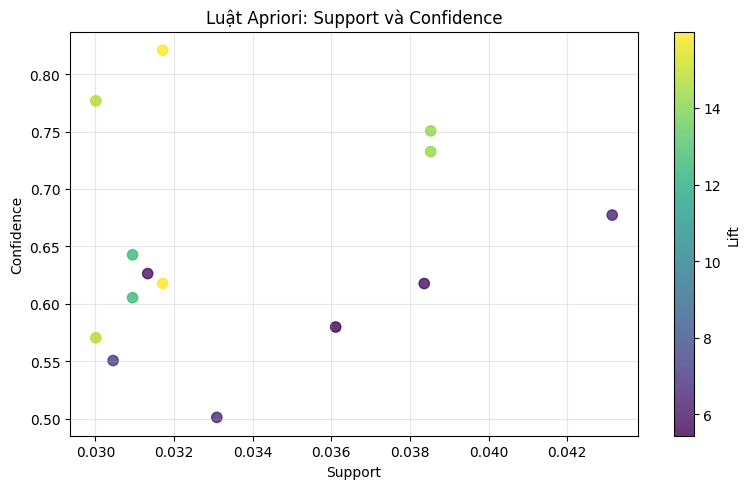

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
if rules_apriori.empty:
    ax.text(0.5, 0.5, "Không có luật thỏa ngưỡng", ha="center", va="center", transform=ax.transAxes)
else:
    points = ax.scatter(rules_apriori["support"], rules_apriori["confidence"], c=rules_apriori["lift"], cmap="viridis", s=55, alpha=0.8)
    fig.colorbar(points, ax=ax, label="Lift")
ax.set(title="Luật Apriori: Support và Confidence", xlabel="Support", ylabel="Confidence")
ax.grid(True, alpha=0.3)
plt.tight_layout()
print(f"Scatter plot support × confidence | {STUDENT_INFO}")
plt.show()


## Câu 12. FP-Growth và so sánh với Apriori


In [ ]:
from mlxtend.frequent_patterns import fpgrowth
frequent_fp = fpgrowth(onehot, min_support=MIN_SUP, use_colnames=True)
frequent_fp = frequent_fp.sort_values("support", ascending=False, kind="stable").reset_index(drop=True)
rules_fp = make_rules(frequent_fp, len(onehot), min_conf=0.50)
if not rules_fp.empty:
    rules_fp = rules_fp.sort_values(["confidence","support"], ascending=False).reset_index(drop=True)
print(f"Số tập phổ biến FP-Growth: {len(frequent_fp)} | Số luật FP-Growth: {len(rules_fp)} | {STUDENT_INFO}")
print(f"Các luật FP-Growth | {STUDENT_INFO}"); display(rules_fp)

apriori_sets = set(frequent_apriori["itemsets"].map(frozenset))
fp_sets = set(frequent_fp["itemsets"].map(frozenset))
common_sets = apriori_sets & fp_sets
apriori_rules_set = set(zip(rules_apriori["antecedents"].map(frozenset), rules_apriori["consequents"].map(frozenset))) if not rules_apriori.empty else set()
fp_rules_set = set(zip(rules_fp["antecedents"].map(frozenset), rules_fp["consequents"].map(frozenset))) if not rules_fp.empty else set()
comparison = pd.DataFrame({
    "Chỉ số":["Số tập phổ biến Apriori","Số tập phổ biến FP-Growth","Tập phổ biến trùng nhau","Số luật Apriori","Số luật FP-Growth","Luật trùng nhau"],
    "Kết quả":[len(apriori_sets),len(fp_sets),len(common_sets),len(apriori_rules_set),len(fp_rules_set),len(apriori_rules_set & fp_rules_set)]
})
print(f"So sánh Apriori và FP-Growth | {STUDENT_INFO}"); display(comparison)
if apriori_sets == fp_sets and apriori_rules_set == fp_rules_set:
    print("Nhận xét: hai thuật toán cho cùng tập phổ biến và luật kết hợp với cùng ngưỡng; khác nhau chủ yếu ở cách tìm kiếm.")
else:
    print("Nhận xét: hai thuật toán cần cho cùng kết quả về tập phổ biến và luật với cùng dữ liệu/ngưỡng. Kiểm tra lại ma trận đầu vào hoặc cấu hình nếu có khác biệt.")
print(STUDENT_INFO)


Số tập phổ biến FP-Growth: 142 | Số luật FP-Growth: 14 | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011
Các luật FP-Growth | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(PINK REGENCY TEACUP AND SAUCER),(GREEN REGENCY TEACUP AND SAUCER),0.038639,0.051336,0.031714,0.820768,15.988282,1.0,0.029730,5.292945,0.975132,0.544340,0.811069,0.719271
1,(PINK REGENCY TEACUP AND SAUCER),(ROSES REGENCY TEACUP AND SAUCER),0.038639,0.052600,0.030010,0.776671,14.765684,1.0,0.027977,4.242181,0.969746,0.490126,0.764272,0.673602
2,(GREEN REGENCY TEACUP AND SAUCER),(ROSES REGENCY TEACUP AND SAUCER),0.051336,0.052600,0.038529,0.750535,14.268798,1.0,0.035829,3.797733,0.980238,0.589076,0.736685,0.741516
3,(ROSES REGENCY TEACUP AND SAUCER),(GREEN REGENCY TEACUP AND SAUCER),0.052600,0.051336,0.038529,0.732497,14.268798,1.0,0.035829,3.546374,0.981546,0.589076,0.718022,0.741516
4,(JUMBO BAG PINK POLKADOT),(JUMBO BAG RED RETROSPOT),0.063702,0.106519,0.043146,0.677308,6.358587,1.0,0.036361,2.768837,0.900069,0.339533,0.638837,0.541182
5,(ALARM CLOCK BAKELIKE GREEN),(ALARM CLOCK BAKELIKE RED),0.048148,0.051116,0.030944,0.642694,12.573307,1.0,0.028483,2.655663,0.967027,0.452936,0.623446,0.624035
6,(JUMBO BAG BAROQUE BLACK WHITE),(JUMBO BAG RED RETROSPOT),0.050016,0.106519,0.031329,0.626374,5.880414,1.0,0.026001,2.391377,0.873640,0.250219,0.581831,0.460246
7,(GREEN REGENCY TEACUP AND SAUCER),(PINK REGENCY TEACUP AND SAUCER),0.051336,0.038639,0.031714,0.617773,15.988282,1.0,0.029730,2.515157,0.988183,0.544340,0.602411,0.719271
8,(JUMBO STORAGE BAG SUKI),(JUMBO BAG RED RETROSPOT),0.062108,0.106519,0.038364,0.617699,5.798977,1.0,0.031749,2.337116,0.882358,0.294515,0.572122,0.488932
9,(ALARM CLOCK BAKELIKE RED),(ALARM CLOCK BAKELIKE GREEN),0.051116,0.048148,0.030944,0.605376,12.573307,1.0,0.028483,2.412051,0.970051,0.452936,0.585415,0.624035


So sánh Apriori và FP-Growth | Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011


,Chỉ số,Kết quả
0,Số tập phổ biến Apriori,142
1,Số tập phổ biến FP-Growth,142
2,Tập phổ biến trùng nhau,142
3,Số luật Apriori,14
4,Số luật FP-Growth,14
5,Luật trùng nhau,14


Nhận xét: hai thuật toán cho cùng tập phổ biến và luật kết hợp với cùng ngưỡng; khác nhau chủ yếu ở cách tìm kiếm.
Thông tin sinh viên: Lê Nguyễn Anh Dự - 6451071011
